# 📊 Notebook 05 — Evaluasi Multi-Horizon & Prediksi Jam ke Depan
**3 Model × 3 Horizon = 9 evaluasi**

Output: tabel perbandingan, grafik forecast, sistem rekomendasi irigasi adaptif

In [1]:
# ── CELL 1: Import & Load Semua Hasil ──────────────────────────
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import json, os, warnings, joblib
warnings.filterwarnings('ignore')
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

HORIZONS   = ['60m','180m','360m']
TARGET_MAP = {'60m':'target_60m','180m':'target_180m','360m':'target_360m'}
MODELS     = ['rf','xgb','lgb']
MODEL_LABEL= {'rf':'Random Forest','xgb':'XGBoost','lgb':'LightGBM'}
COLORS     = {'rf':'#1565C0','xgb':'#43A047','lgb':'#FF6F00'}

# Load metrik tersimpan
with open('models/rf_metrics_all.json')  as f: rf_m  = json.load(f)
with open('models/xgb_metrics_all.json') as f: xgb_m = json.load(f)
with open('models/lgb_metrics_all.json') as f: lgb_m = json.load(f)

ALL_METRICS = {'rf': rf_m, 'xgb': xgb_m, 'lgb': lgb_m}
print('[OK] Semua metrik berhasil dimuat')


[OK] Semua metrik berhasil dimuat


In [2]:
# ── CELL 2: Tabel Perbandingan Lengkap ─────────────────────────
print('=== 📊 Perbandingan Model — Semua Horizon ===')
rows = []
for h in HORIZONS:
    for mdl in MODELS:
        mt = ALL_METRICS[mdl][h]['test_metrics']
        rows.append({
            'Horizon': h, 'Model': MODEL_LABEL[mdl],
            'MAE(%)': round(mt['MAE'],4), 'RMSE(%)': round(mt['RMSE'],4),
            'R²': round(mt['R2'],4), 'MAPE(%)': round(mt['MAPE'],2)
        })

df_comp = pd.DataFrame(rows)
print(df_comp.to_string(index=False))

# Simpan tabel
df_comp.to_csv('dataset/ringkasan_evaluasi_multihorizon.csv', index=False)
print('\n[OK] Tabel disimpan: dataset/ringkasan_evaluasi_multihorizon.csv')


=== 📊 Perbandingan Model — Semua Horizon ===
Horizon         Model  MAE(%)  RMSE(%)      R²  MAPE(%)
    60m Random Forest  2.6555   3.3696 -2.1588     4.11
    60m       XGBoost  2.4326   3.0025 -1.5080     3.76
    60m      LightGBM  2.6715   3.3766 -2.1720     4.14
   180m Random Forest  3.0849   3.8409 -3.1087     4.77
   180m       XGBoost  3.4877   4.1139 -3.7136     5.38
   180m      LightGBM  3.5414   4.1598 -3.8193     5.46
   360m Random Forest  3.5703   4.3419 -4.2580     5.52
   360m       XGBoost  3.8826   4.6112 -4.9305     5.99
   360m      LightGBM  3.7952   4.5888 -4.8730     5.86

[OK] Tabel disimpan: dataset/ringkasan_evaluasi_multihorizon.csv


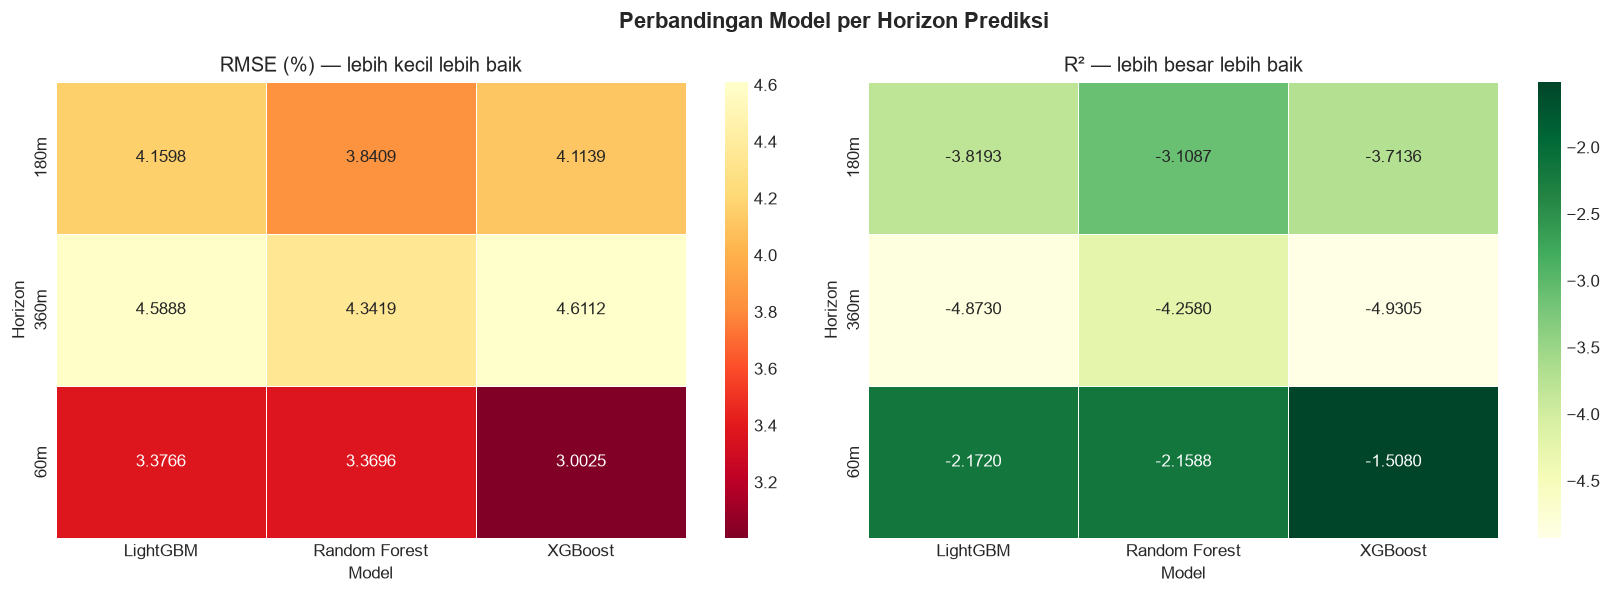

[OK] Heatmap metrik disimpan


In [3]:
# ── CELL 3: Heatmap Metrik RMSE ────────────────────────────────
pivot_rmse = df_comp.pivot(index='Horizon', columns='Model', values='RMSE(%)')
pivot_r2   = df_comp.pivot(index='Horizon', columns='Model', values='R²')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Perbandingan Model per Horizon Prediksi', fontsize=13, fontweight='bold')

sns_kw = dict(annot=True, fmt='.4f', cmap='YlOrRd_r', linewidths=0.5)
import seaborn as sns
sns.heatmap(pivot_rmse, ax=axes[0], **sns_kw)
axes[0].set_title('RMSE (%) — lebih kecil lebih baik')

sns_kw2 = dict(annot=True, fmt='.4f', cmap='YlGn', linewidths=0.5)
sns.heatmap(pivot_r2, ax=axes[1], **sns_kw2)
axes[1].set_title('R² — lebih besar lebih baik')

plt.tight_layout()
plt.savefig('dataset/plot_heatmap_metrik.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Heatmap metrik disimpan')


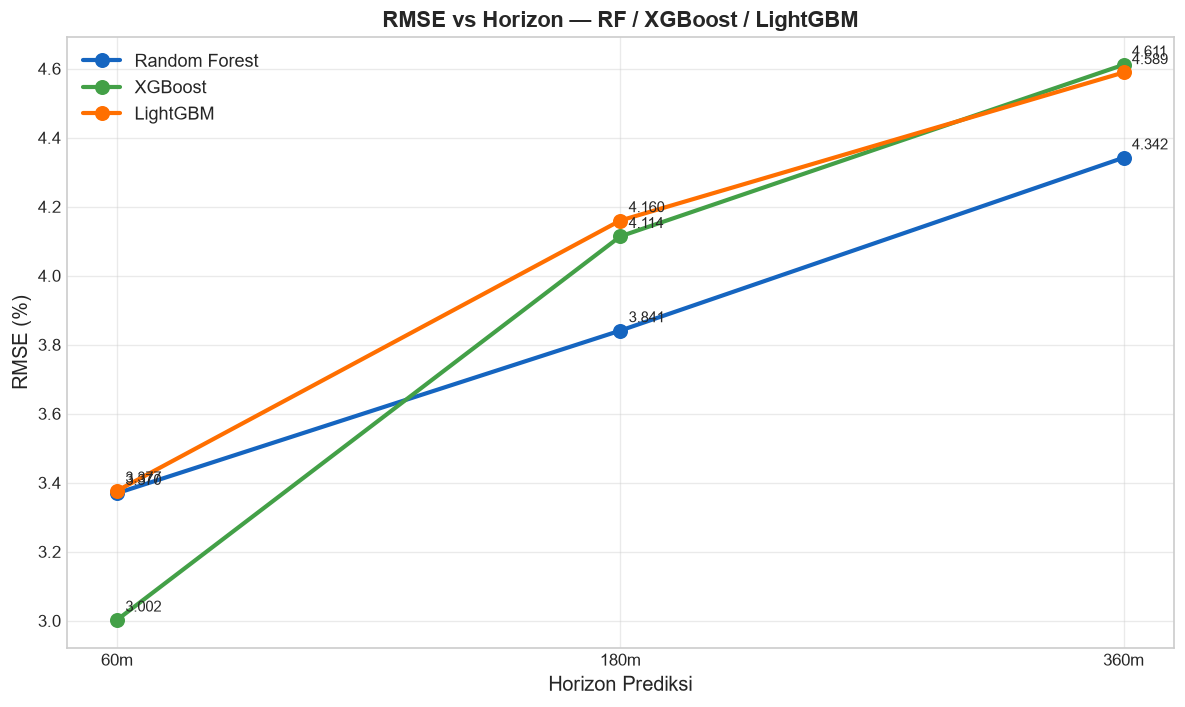

In [4]:
# ── CELL 4: RMSE vs Horizon Chart ──────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
for mdl in MODELS:
    rmse_list = [ALL_METRICS[mdl][h]['test_metrics']['RMSE'] for h in HORIZONS]
    ax.plot(HORIZONS, rmse_list, marker='o', linewidth=2.5, markersize=8,
            color=COLORS[mdl], label=MODEL_LABEL[mdl])
    for h, v in zip(HORIZONS, rmse_list):
        ax.annotate(f'{v:.3f}', (h, v), textcoords='offset points',
                    xytext=(5,5), fontsize=9)

ax.set_xlabel('Horizon Prediksi', fontsize=12)
ax.set_ylabel('RMSE (%)', fontsize=12)
ax.set_title('RMSE vs Horizon — RF / XGBoost / LightGBM', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('dataset/plot_rmse_vs_horizon.png', dpi=150, bbox_inches='tight')
plt.show()


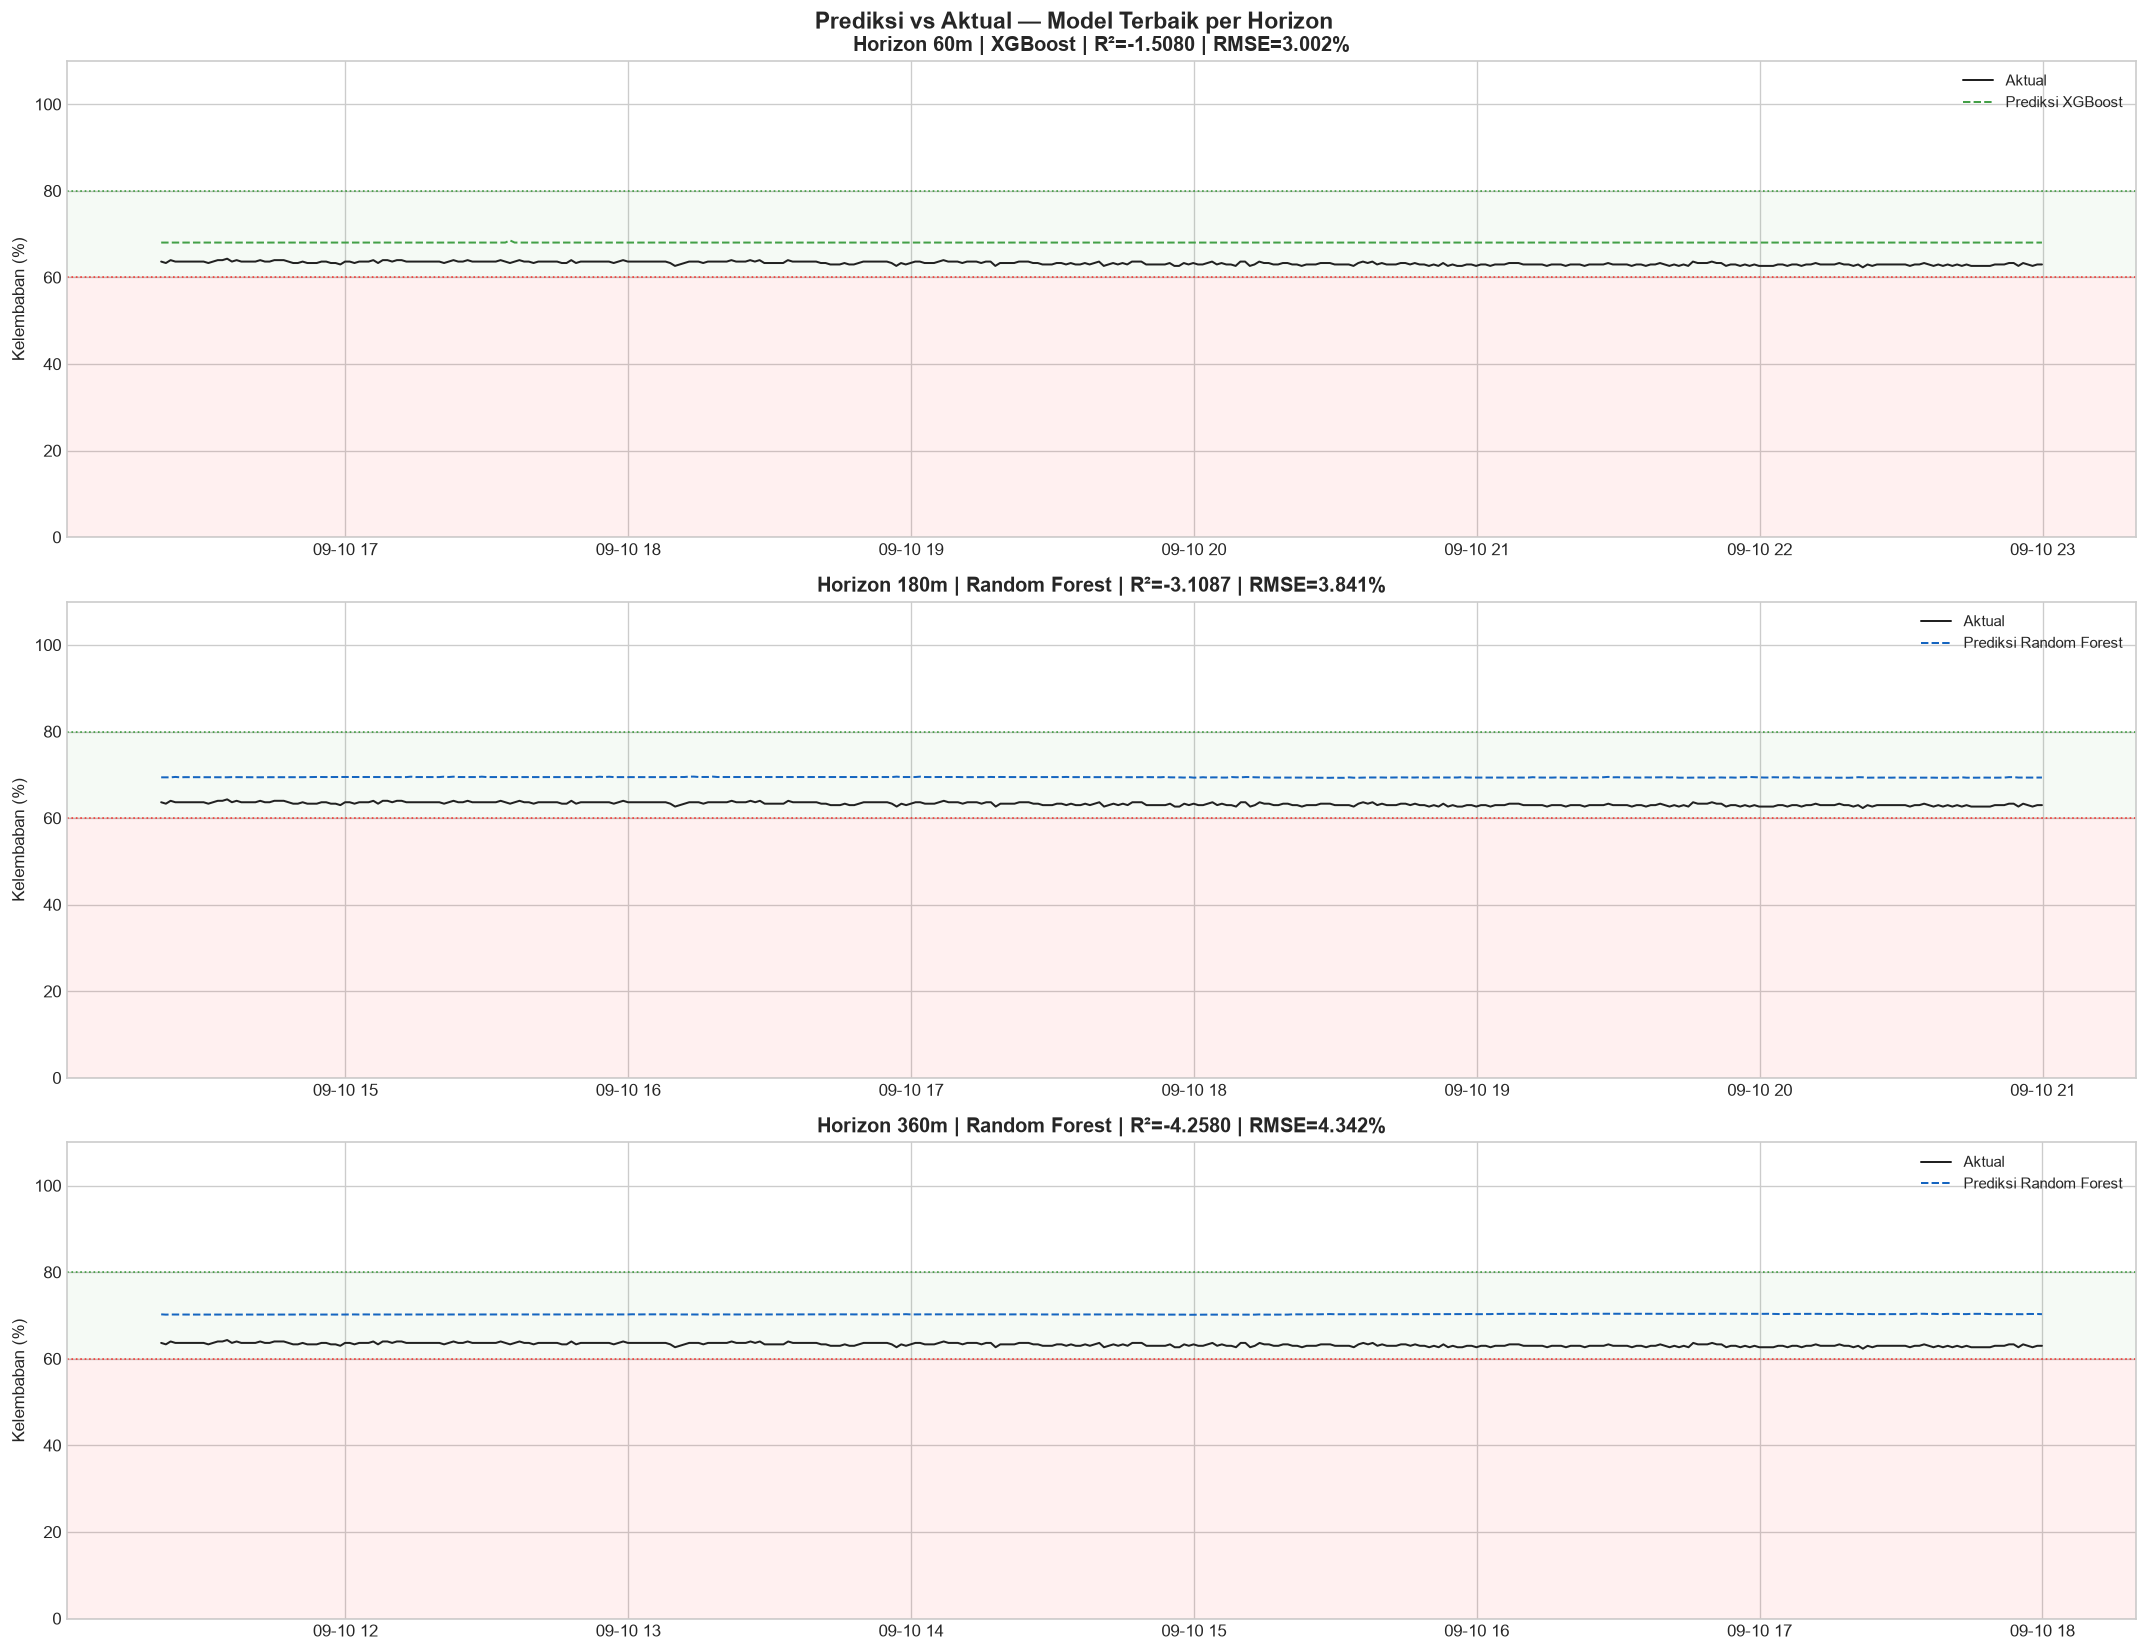

[OK] Plot prediksi multi-horizon disimpan


In [5]:
# ── CELL 5: Prediksi vs Aktual per Horizon (Model Terbaik) ─────
fig, axes = plt.subplots(3, 1, figsize=(18, 14), sharex=False)
fig.suptitle('Prediksi vs Aktual — Model Terbaik per Horizon', fontsize=14, fontweight='bold')

for idx, horizon in enumerate(HORIZONS):
    target = TARGET_MAP[horizon]
    # Pilih model terbaik berdasarkan R²
    best_mdl = max(MODELS, key=lambda m: ALL_METRICS[m][horizon]['test_metrics']['R2'])
    r2_best  = ALL_METRICS[best_mdl][horizon]['test_metrics']['R2']
    rmse_best= ALL_METRICS[best_mdl][horizon]['test_metrics']['RMSE']

    df_pred = pd.read_csv(f'dataset/prediksi_{best_mdl}_{horizon}.csv',
                           parse_dates=['waktu_pembacaan'])
    n_plot  = 400
    df_p    = df_pred.tail(n_plot)
    col_pred= f'prediksi_{best_mdl}'

    axes[idx].plot(df_p['waktu_pembacaan'], df_p[target],
                   color='#212121', linewidth=1.2, label='Aktual')
    axes[idx].plot(df_p['waktu_pembacaan'], df_p[col_pred],
                   color=COLORS[best_mdl], linewidth=1.2, linestyle='--',
                   label=f'Prediksi {MODEL_LABEL[best_mdl]}')

    axes[idx].axhspan(0,  60, alpha=0.06, color='red')
    axes[idx].axhspan(60, 80, alpha=0.04, color='green')
    axes[idx].axhline(60, color='red',   linestyle=':', alpha=0.7, linewidth=1)
    axes[idx].axhline(80, color='green', linestyle=':', alpha=0.7, linewidth=1)

    axes[idx].set_ylabel('Kelembaban (%)')
    axes[idx].set_title(
        f'Horizon {horizon} | {MODEL_LABEL[best_mdl]} | R²={r2_best:.4f} | RMSE={rmse_best:.3f}%',
        fontweight='bold')
    axes[idx].legend(fontsize=9)
    axes[idx].set_ylim(0, 110)

plt.tight_layout()
plt.savefig('dataset/plot_prediksi_multihorizon.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot prediksi multi-horizon disimpan')


In [6]:
# ── CELL 6: Simulasi Prediksi Real-Time (Multi-Jam ke Depan) ────
print('=== 🤖 SIMULASI PREDIKSI MULTI-HORIZON (Real-Time) ===')
print()

# Tentukan model terbaik per horizon
best_model_per_horizon = {}
for horizon in HORIZONS:
    best_mdl = max(MODELS, key=lambda m: ALL_METRICS[m][horizon]['test_metrics']['R2'])
    best_model_per_horizon[horizon] = best_mdl
    print(f'  Horizon {horizon}: Model terbaik = {MODEL_LABEL[best_mdl]}'
          f'  (R²={ALL_METRICS[best_mdl][horizon]["test_metrics"]["R2"]:.4f})')

print()
results_forecast = {}

for horizon in HORIZONS:
    best_mdl = best_model_per_horizon[horizon]
    target   = TARGET_MAP[horizon]

    # Load model & data
    model = joblib.load(f'models/{best_mdl}_model_{horizon}.pkl')
    df_test = pd.read_csv(f'dataset/data_test_{horizon}.csv',
                           parse_dates=['waktu_pembacaan'])
    with open(f'models/feature_cols_{horizon}.json') as f:
        feat_cols = json.load(f)

    # Ambil 10 sampel terakhir sebagai "data real-time"
    n_sample  = 10
    df_sample = df_test.tail(n_sample).copy()
    X_sample  = df_sample[feat_cols].values
    y_actual  = df_sample[target].values
    y_pred    = model.predict(X_sample)
    waktu     = df_sample['waktu_pembacaan'].values

    results_forecast[horizon] = {
        'model'   : MODEL_LABEL[best_mdl],
        'waktu'   : [str(w) for w in waktu],
        'aktual'  : y_actual.tolist(),
        'prediksi': y_pred.tolist(),
    }

    print(f'  === Horizon {horizon} ({MODEL_LABEL[best_mdl]}) ===')
    print(f'  {"Waktu":<22} {"Aktual":>8} {"Prediksi":>10} {"Error":>8}')
    print(f'  {"-"*52}')
    for w, a, p in zip(waktu, y_actual, y_pred):
        print(f'  {str(w)[:19]:<22} {a:>8.2f} {p:>10.2f} {abs(a-p):>8.2f}')
    print()

# Simpan hasil
with open('dataset/hasil_forecast_realtime.json', 'w') as f:
    json.dump(results_forecast, f, indent=2)
print('[OK] Hasil forecast disimpan: dataset/hasil_forecast_realtime.json')


=== 🤖 SIMULASI PREDIKSI MULTI-HORIZON (Real-Time) ===

  Horizon 60m: Model terbaik = XGBoost  (R²=-1.5080)
  Horizon 180m: Model terbaik = Random Forest  (R²=-3.1087)
  Horizon 360m: Model terbaik = Random Forest  (R²=-4.2580)

  === Horizon 60m (XGBoost) ===
  Waktu                    Aktual   Prediksi    Error
  ----------------------------------------------------
  2026-09-10T22:50:53       63.00      68.06     5.06
  2026-09-10T22:51:53       63.00      68.06     5.06
  2026-09-10T22:52:53       63.33      68.06     4.72
  2026-09-10T22:53:53       63.33      68.06     4.72
  2026-09-10T22:54:53       62.67      68.06     5.39
  2026-09-10T22:55:53       63.33      68.06     4.72
  2026-09-10T22:56:53       63.00      68.06     5.06
  2026-09-10T22:57:53       62.67      68.06     5.39
  2026-09-10T22:58:53       63.00      68.06     5.06
  2026-09-10T22:59:53       63.00      68.06     5.06

  === Horizon 180m (Random Forest) ===
  Waktu                    Aktual   Prediksi    Er

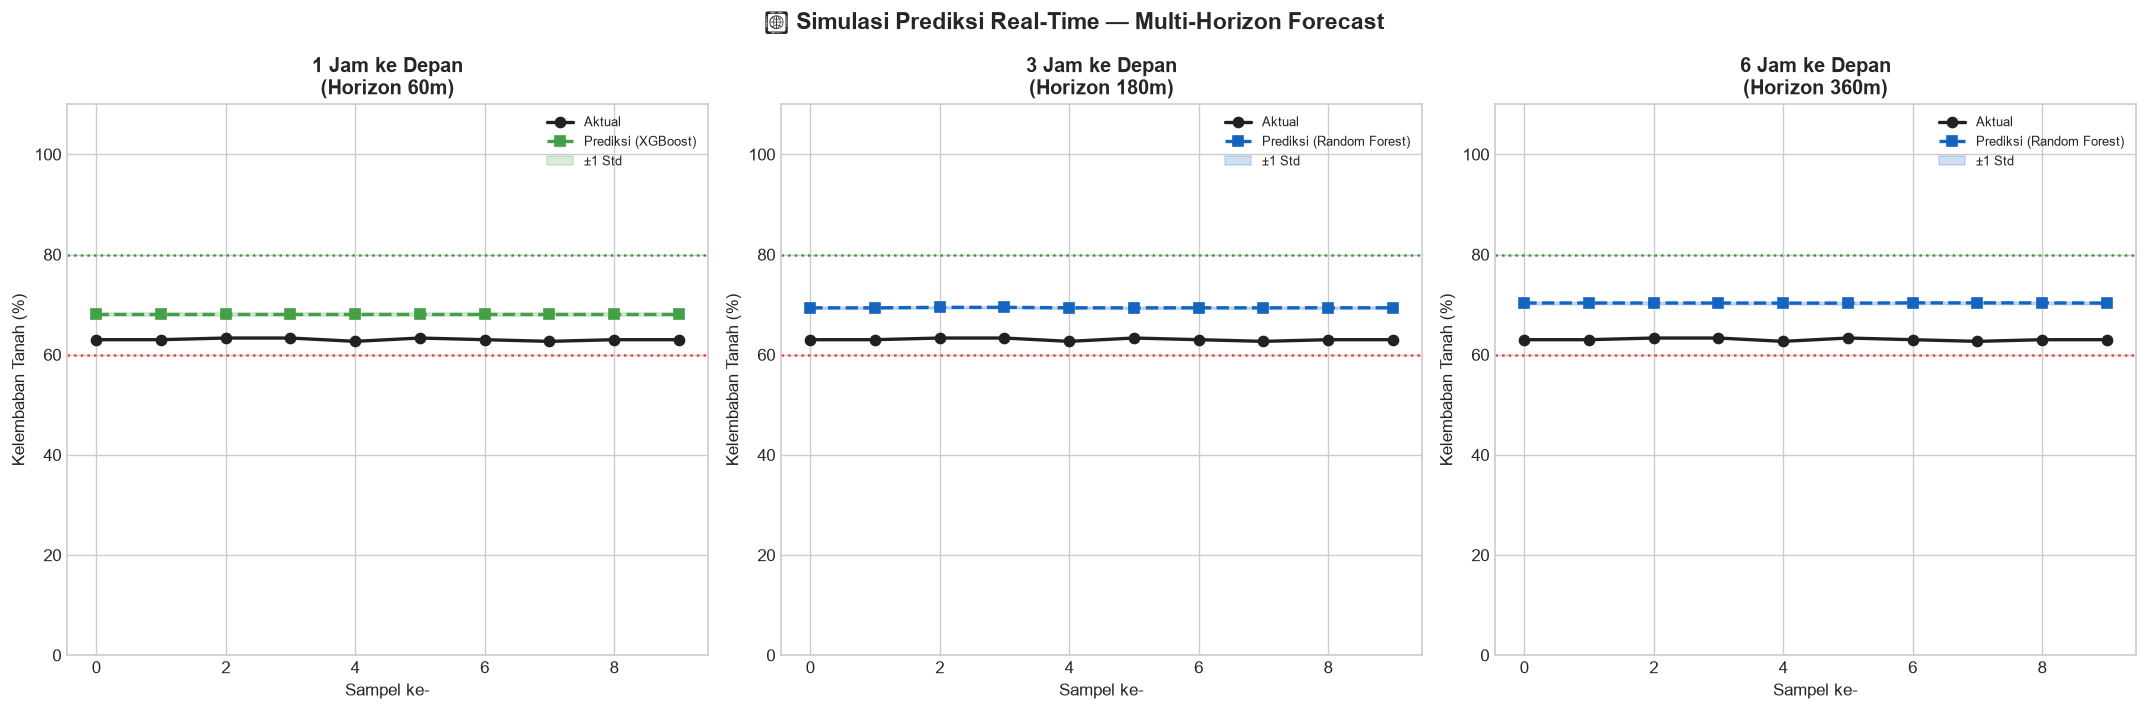

[OK] Plot forecast multi-jam disimpan


In [7]:
# ── CELL 7: Grafik Forecast Multi-Jam ke Depan ─────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('🔮 Simulasi Prediksi Real-Time — Multi-Horizon Forecast',
             fontsize=14, fontweight='bold')

LABEL_MAP = {'60m':'1 Jam ke Depan','180m':'3 Jam ke Depan','360m':'6 Jam ke Depan'}

for idx, horizon in enumerate(HORIZONS):
    ax      = axes[idx]
    res     = results_forecast[horizon]
    aktual  = np.array(res['aktual'])
    prediksi= np.array(res['prediksi'])
    x_idx   = range(len(aktual))

    ax.plot(x_idx, aktual,   'o-', color='#212121', linewidth=2,
            markersize=6, label='Aktual')
    ax.plot(x_idx, prediksi, 's--', color=COLORS[best_model_per_horizon[horizon]],
            linewidth=2, markersize=6, label=f'Prediksi ({res["model"]})')

    # Confidence band ± std residual
    resid_std = np.std(aktual - prediksi)
    ax.fill_between(x_idx,
                    prediksi - resid_std,
                    prediksi + resid_std,
                    alpha=0.2, color=COLORS[best_model_per_horizon[horizon]],
                    label='±1 Std')

    ax.axhline(60, color='red',   linestyle=':', alpha=0.7, linewidth=1.5)
    ax.axhline(80, color='green', linestyle=':', alpha=0.7, linewidth=1.5)
    ax.set_xlabel('Sampel ke-')
    ax.set_ylabel('Kelembaban Tanah (%)')
    ax.set_title(f'{LABEL_MAP[horizon]}\n(Horizon {horizon})', fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylim(0, 110)

plt.tight_layout()
plt.savefig('dataset/plot_forecast_multijam.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot forecast multi-jam disimpan')


In [8]:
# ── CELL 8: Sistem Rekomendasi Irigasi Adaptif ──────────────────
print('=== [DONE] SISTEM REKOMENDASI IRIGASI ADAPTIF GAMBUT ===')
print()

THRESHOLD = {'KRITIS':60,'WASPADA':70,'OPTIMAL':80,'LEMBAB':90}

def rekomendasi_irigasi(pred):
    if pred < 60:   return 'IRIGASI SEGERA',    'KRITIS',  '#D32F2F'
    elif pred < 70: return 'BERSIAP IRIGASI',   'WASPADA', '#F57C00'
    elif pred < 80: return 'KONDISI OPTIMAL',   'OPTIMAL', '#2E7D32'
    elif pred < 90: return 'PERHATIKAN DRAINASE','LEMBAB',  '#1565C0'
    else:           return 'HENTIKAN IRIGASI',  'JENUH',   '#6A1B9A'

# Gunakan prediksi horizon 60m untuk rekomendasi utama
best_60m = best_model_per_horizon['60m']
target60 = TARGET_MAP['60m']
df_test60 = pd.read_csv(f'dataset/data_test_60m.csv', parse_dates=['waktu_pembacaan'])
df_pred60 = pd.read_csv(f'dataset/prediksi_{best_60m}_60m.csv', parse_dates=['waktu_pembacaan'])

df_rek = df_test60[['waktu_pembacaan', target60]].copy()
df_rek['prediksi_60m'] = df_pred60[f'prediksi_{best_60m}'].values

df_rek[['rekomendasi','status','warna']] = df_rek['prediksi_60m'].apply(
    lambda x: pd.Series(rekomendasi_irigasi(x))
)

stat = df_rek['status'].value_counts()
stat_pct = (stat / len(df_rek) * 100).round(2)
df_stat = pd.DataFrame({'Jumlah': stat, 'Persentase(%)': stat_pct})
print('Distribusi Status Irigasi (Data Test):')
print(df_stat.to_string())

# Simpan
df_rek.to_csv('dataset/hasil_rekomendasi_irigasi.csv', index=False)
print('\n[OK] Rekomendasi irigasi disimpan: dataset/hasil_rekomendasi_irigasi.csv')


=== [DONE] SISTEM REKOMENDASI IRIGASI ADAPTIF GAMBUT ===

Distribusi Status Irigasi (Data Test):
         Jumlah  Persentase(%)
status                        
WASPADA   18060          100.0

[OK] Rekomendasi irigasi disimpan: dataset/hasil_rekomendasi_irigasi.csv


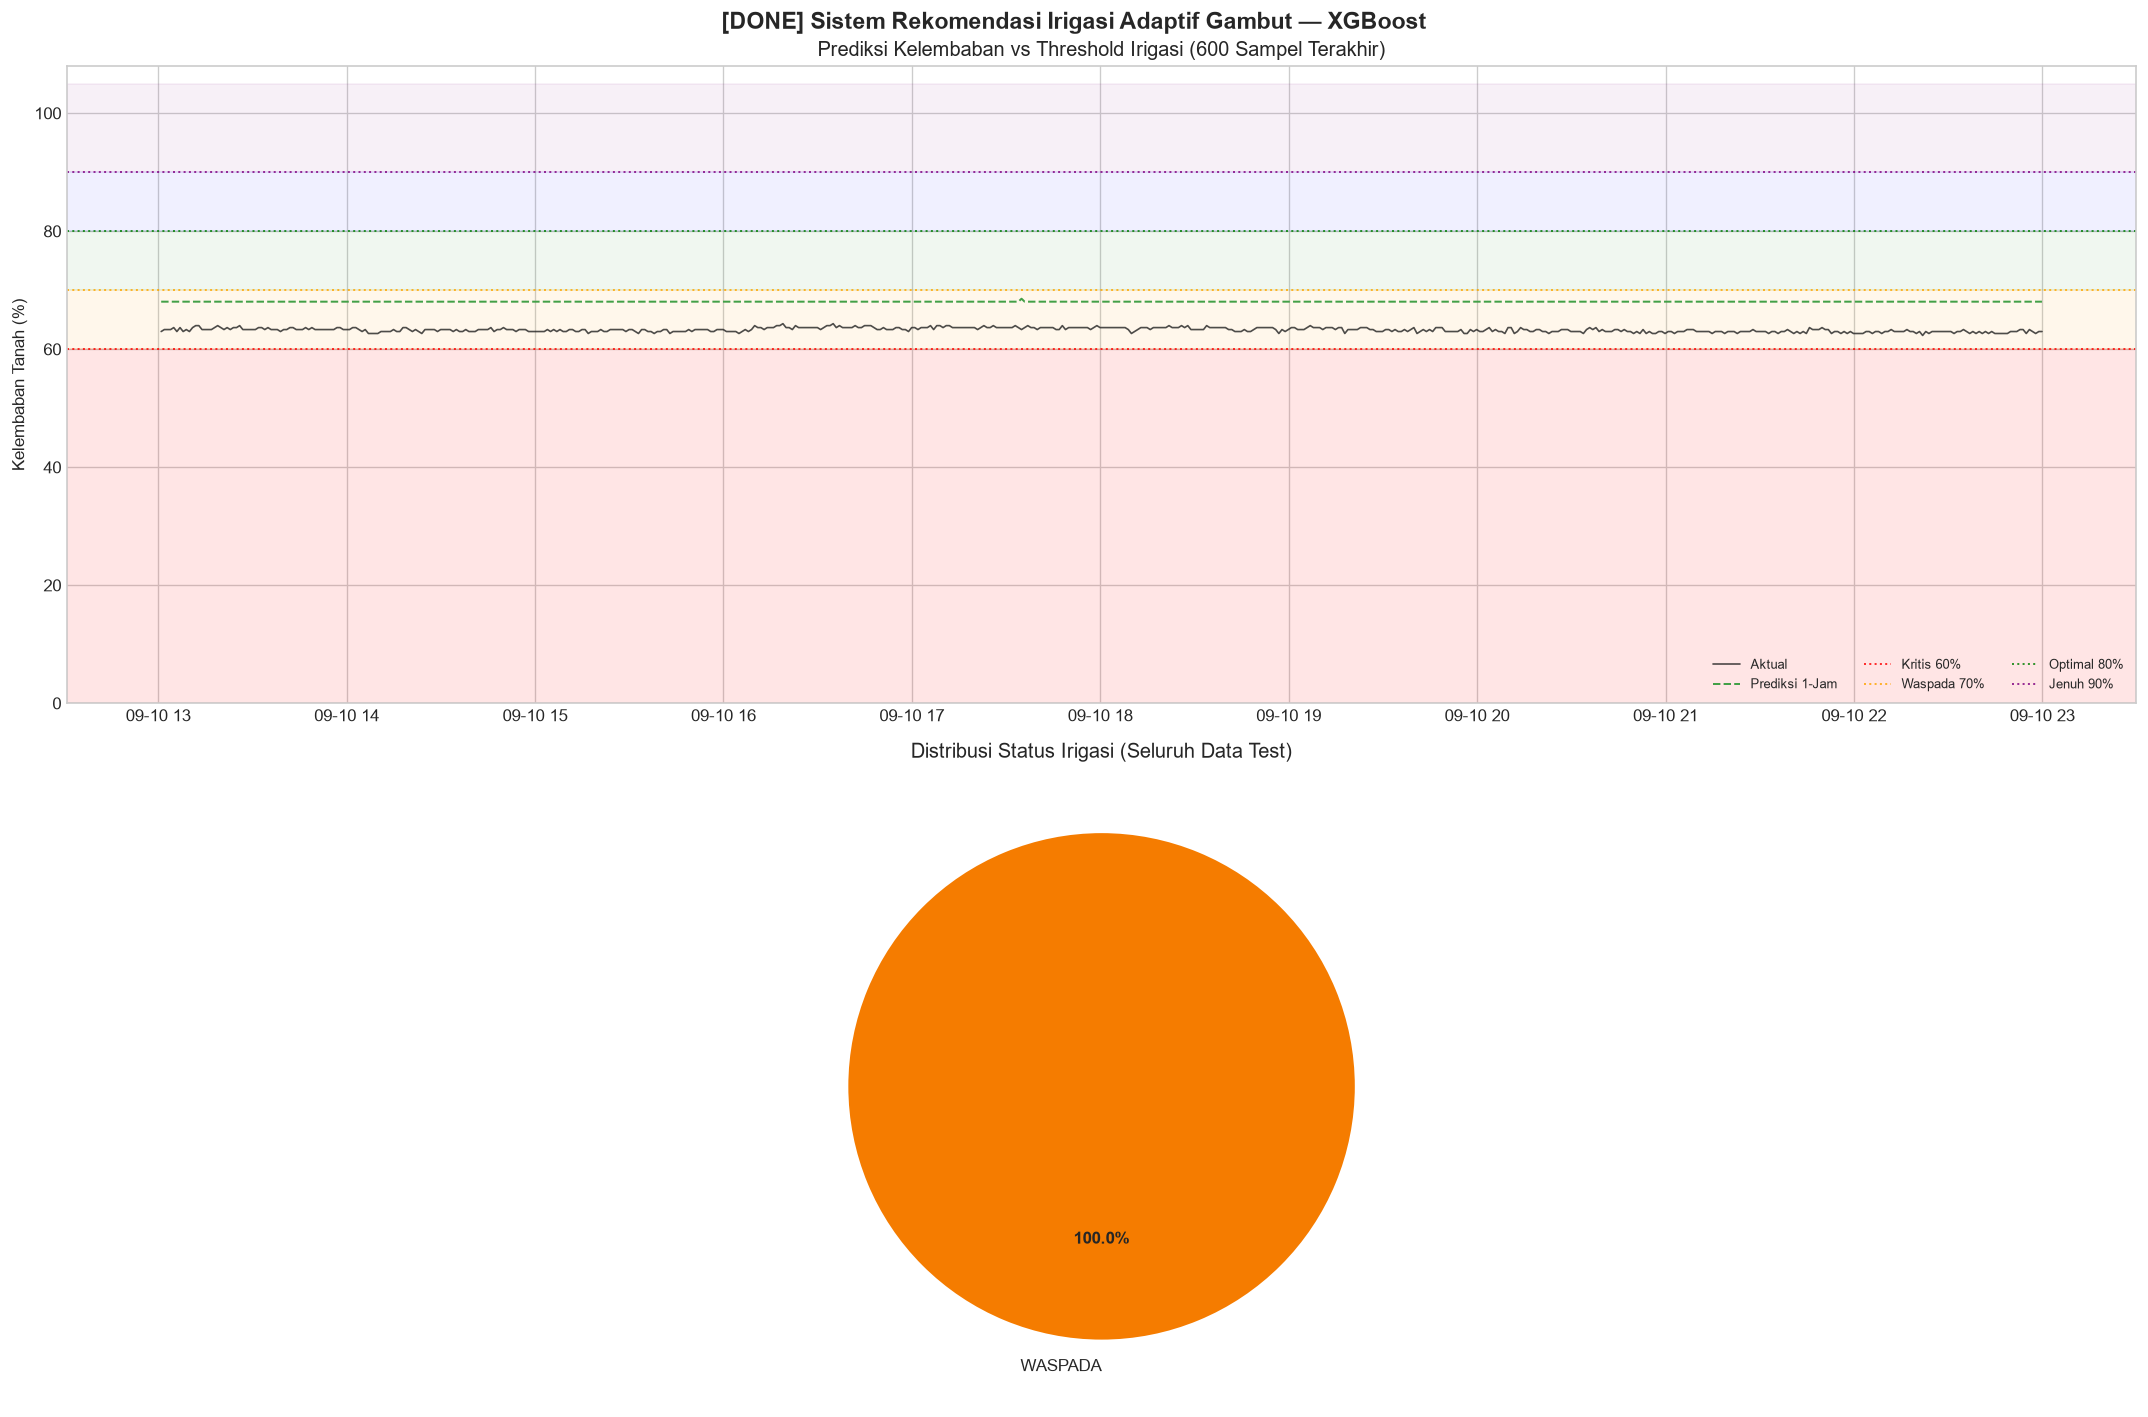

[OK] Plot rekomendasi irigasi disimpan


In [9]:
# ── CELL 9: Visualisasi Rekomendasi Irigasi ─────────────────────
fig, axes = plt.subplots(2, 1, figsize=(18, 12))
fig.suptitle(f'[DONE] Sistem Rekomendasi Irigasi Adaptif Gambut — {MODEL_LABEL[best_60m]}',
             fontsize=14, fontweight='bold')

warna_map = {'KRITIS':'#D32F2F','WASPADA':'#F57C00',
             'OPTIMAL':'#2E7D32','LEMBAB':'#1565C0','JENUH':'#6A1B9A'}
n_plot = 600
df_p   = df_rek.tail(n_plot)

# Plot 1: Time series + threshold
axes[0].plot(df_p['waktu_pembacaan'], df_p[target60],
             color='#212121', linewidth=1, label='Aktual', alpha=0.8)
axes[0].plot(df_p['waktu_pembacaan'], df_p['prediksi_60m'],
             color='#43A047', linewidth=1.2, linestyle='--', label='Prediksi 1-Jam')
axes[0].axhspan(0,  60, alpha=0.10, color='red')
axes[0].axhspan(60, 70, alpha=0.08, color='orange')
axes[0].axhspan(70, 80, alpha=0.06, color='green')
axes[0].axhspan(80, 90, alpha=0.06, color='blue')
axes[0].axhspan(90, 105,alpha=0.06, color='purple')
for thresh, label, col in [
    (60,'Kritis 60%','red'),(70,'Waspada 70%','orange'),
    (80,'Optimal 80%','green'),(90,'Jenuh 90%','purple')]:
    axes[0].axhline(thresh, color=col, linestyle=':', alpha=0.8, linewidth=1.2, label=label)
axes[0].set_ylabel('Kelembaban Tanah (%)')
axes[0].set_title('Prediksi Kelembaban vs Threshold Irigasi (600 Sampel Terakhir)')
axes[0].legend(fontsize=8, loc='lower right', ncol=3)
axes[0].set_ylim(0, 108)

# Plot 2: Pie chart
stat_data = df_rek['status'].value_counts()
pie_colors = [warna_map.get(s,'gray') for s in stat_data.index]
wedges, texts, autotexts = axes[1].pie(
    stat_data.values, labels=stat_data.index,
    autopct='%1.1f%%', colors=pie_colors, startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2})
for at in autotexts:
    at.set_fontsize(10); at.set_fontweight('bold')
axes[1].set_title('Distribusi Status Irigasi (Seluruh Data Test)')

plt.tight_layout()
plt.savefig('dataset/plot_rekomendasi_irigasi.png', dpi=150, bbox_inches='tight')
plt.show()
print('[OK] Plot rekomendasi irigasi disimpan')


In [10]:
# ── CELL 10: Simpan Model Registry & Kesimpulan Akhir ───────────
registry = {}
for horizon in HORIZONS:
    registry[horizon] = {}
    for mdl in MODELS:
        mt = ALL_METRICS[mdl][horizon]['test_metrics']
        registry[horizon][MODEL_LABEL[mdl]] = mt

with open('models/model_registry.json','w') as f:
    json.dump(registry, f, indent=2)

print('=' * 65)
print('🏆 KESIMPULAN AKHIR — PREDIKSI KELEMBABAN TANAH GAMBUT')
print('=' * 65)
print()

for horizon in HORIZONS:
    best_mdl  = max(MODELS, key=lambda m: ALL_METRICS[m][horizon]['test_metrics']['R2'])
    mt        = ALL_METRICS[best_mdl][horizon]['test_metrics']
    h_minutes = {'60m':60,'180m':180,'360m':360}[horizon]
    print(f'  Horizon {horizon} ({h_minutes} menit ke depan):')
    print(f'    Model Terbaik : {MODEL_LABEL[best_mdl]}')
    print(f'    MAE  = {mt["MAE"]:.4f}%  |  RMSE = {mt["RMSE"]:.4f}%')
    print(f'    R²   = {mt["R2"]:.4f}   |  MAPE = {mt["MAPE"]:.2f}%')
    print()

print('📁 File Output:')
for h in HORIZONS:
    for mdl in MODELS:
        print(f'  models/{mdl}_model_{h}.pkl')
print()
print('[OK] Analisis Machine Learning Irigasi Gambut Selesai!')
print('   3 Node ESP32 | 3 Model | 3 Horizon Prediksi')


🏆 KESIMPULAN AKHIR — PREDIKSI KELEMBABAN TANAH GAMBUT

  Horizon 60m (60 menit ke depan):
    Model Terbaik : XGBoost
    MAE  = 2.4326%  |  RMSE = 3.0025%
    R²   = -1.5080   |  MAPE = 3.76%

  Horizon 180m (180 menit ke depan):
    Model Terbaik : Random Forest
    MAE  = 3.0849%  |  RMSE = 3.8409%
    R²   = -3.1087   |  MAPE = 4.77%

  Horizon 360m (360 menit ke depan):
    Model Terbaik : Random Forest
    MAE  = 3.5703%  |  RMSE = 4.3419%
    R²   = -4.2580   |  MAPE = 5.52%

📁 File Output:
  models/rf_model_60m.pkl
  models/xgb_model_60m.pkl
  models/lgb_model_60m.pkl
  models/rf_model_180m.pkl
  models/xgb_model_180m.pkl
  models/lgb_model_180m.pkl
  models/rf_model_360m.pkl
  models/xgb_model_360m.pkl
  models/lgb_model_360m.pkl

[OK] Analisis Machine Learning Irigasi Gambut Selesai!
   3 Node ESP32 | 3 Model | 3 Horizon Prediksi
